# Tutorial 02: Build your own case
This notebook will guide you through building a case of your own, starting from the built-in defaults.\
You will learn how to:
- look at the built-in defaults;
- replace them one block at a time with `settings`: column, gas, isotherm, kinetics, sorbent, reference state, steps;
- export your settings to a file (a preset), and run from it;
- change one setting at a time (here the regeneration temperature);
- save the complete case (every field) to a file, to look at it or share it.

The result is a 2D temperature swing adsorption (TSA) at atmospheric pressure on zeolite 13X:
- the bed is loaded with 12 % CO2 in N2;
- then it is heated through the wall to release the CO2.

### Overview
- **Case:** [`../cases/02_custom_case.json`](../cases/02_custom_case.json)
- **Runtime:** three step runs of about two and a half minutes each, on a coarse 2D grid.
- **Memory and disk:** under 1 GB of memory; about 0.3 GB on disk for the three runs.
- **Same tutorial without a notebook:** the terminal commands at the end.

Where the numbers come from:
- The 13X properties and the isotherm come from the validation of the [pyDAC paper](https://doi.org/10.26434/chemrxiv.15010382/v1) ([tutorial 06](06_breakthrough_validation.ipynb)).
- The isotherm is the competitive Sips isotherm of CO2 and N2 on 13X of Hefti et al.,\
  *Microporous Mesoporous Mater.* 215 (2015) 215–228.
- The column and the steps around them are an *example*, not a design.

### Before you start
1. Install pyDAC and select its kernel, following [tutorial 01](01_first_steps.ipynb).
2. Run the cells in order, from the top.

In [1]:
# Import necessary libraries
import json
import tempfile
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

import pydac

# The case file of this tutorial, and the two cycle steps it runs
CASE = Path("../cases/02_custom_case.json")
STEPS = ["startup", "w_des"]

## The defaults

Call `load_case()` without a file to build the complete default case. It returns a pyDAC config object.

The `resolved()` helper in the next cell turns that object into a regular Python dictionary: \
it writes the case to a temporary JSON file, then reads the JSON back. \
This makes the full case easy to inspect and print. The temporary file is deleted automatically.

We print the whole case below: it is about 700 lines.

Prefer to browse it in your editor?
- In [tutorial 01](01_first_steps.ipynb) you already saved a complete case, with `export_case`.
- Open it here: `output_cases/01_full_case.json` (next to this notebook).
- It is the built-in case plus the small preset of [tutorial 01](01_first_steps.ipynb) (a coarser grid and the plot options),\
  so it looks almost the same as the defaults.
- To save the pure defaults yourself:\
  `pydac.export_case(pydac.load_case(), "output_cases/defaults.json")`.

In [2]:
# The complete case as a dictionary, read back from its export (every field).
def resolved(case):
    with tempfile.TemporaryDirectory() as folder:
        path = pydac.export_case(case, Path(folder) / "case.json")
        return json.loads(path.read_text())

# The built-in case, complete (~700 lines)
everything = resolved(pydac.load_case())
print(json.dumps(everything, indent=1))

{
 "execution": {
  "compute_numerical_sparsity": false,
  "css_probe_step": null,
  "css_tolerance": 0.005,
  "cvode_sparsity_mode": "pde_only",
  "cycle_options": {},
  "cycle_steps": null,
  "extra_tag": null,
  "generate_kpi_outputs": true,
  "keep_only_final_cycle": false,
  "max_cycles": 50,
  "output_root": "simulation_results",
  "plot_cyclic_profiles": true,
  "plot_final_cycle_profiles": false,
  "plot_format": "pdf",
  "plot_profiles": false,
  "print_cycle_build": true,
  "print_to_terminal": true,
  "require_css": true,
  "resume_from_cycle": null,
  "solve": true,
  "step_options": {},
  "termination_mode": null,
  "use_sparsity": true
 },
 "schema_version": 8,
 "simulation": {
  "adsorption": {
   "equilibrium_systems": {
    "TothGABWADST": {
     "datasets": {
      "Toth": "Cleaned-Toth"
     },
     "parameters": {}
    }
   },
   "kinetics": {
    "CO2": {
     "model": "LDF",
     "parameters": {
      "k_LDF_s_inv": 0.003
     }
    },
    "H2O": {
     "model": "

The full case is a large structure, so let's not get lost in it.\
We look at it in three steps:
1. **List the sections**: first the top-level ones
2. **Then** those inside `simulation`.
3. **Inspect** the blocks we are going to replace below (geometry, mixture, isotherm, sorbent, reference).

In [3]:
# Let's print the top-level keys of the complete case and explore the simulation section
print("List of sections (top-level keys):")
print(list(everything))
print("List of keys in the simulation section:")
print(list(everything["simulation"]), "\n")

simulation_section = resolved(pydac.load_case())["simulation"]

# A few blocks we are going to replace
print("Simulation section to be replaced:")
print("geometry:", simulation_section["geometry"])
print("mixture: ", simulation_section["mixture"])
print("isotherm:", list(simulation_section["adsorption"]["equilibrium_systems"]))
print("sorbent: ", {key: simulation_section["sorbent"][key] for key in ["density_kg_m3", "heat_capacity", "heats_of_adsorption_J_mol"]})
print("reference:", simulation_section["reference"])


List of sections (top-level keys):
['execution', 'schema_version', 'simulation']
List of keys in the simulation section:
['adsorption', 'bed', 'cycle', 'geometry', 'grid', 'mixture', 'reference', 'solver', 'sorbent', 'wall'] 

Simulation section to be replaced:
geometry: {'aspect_ratio': 0.5, 'length_m': 0.06827840632552958, 'radius_m': 0.06827840632552958, 'specified_by': 'volume_aspect_ratio', 'volume_m3': 0.001}
mixture:  {'adsorbates': ['CO2', 'H2O'], 'closure_species': 'N2', 'species': ['CO2', 'H2O', 'O2', 'N2']}
isotherm: ['TothGABWADST']
sorbent:  {'density_kg_m3': 744.0, 'heat_capacity': {'model': 'Low2023', 'parameters': {'a_J_K_per_kg': -32300000.0, 'b_J_per_kgK2': 2.27, 'c_J_per_kgK': -994.0}}, 'heats_of_adsorption_J_mol': {'CO2': -81000.0, 'H2O': -46000.0}}
reference: {'co2_mole_fraction': 0.0004, 'pressure_Pa': 101325.0, 'relative_humidity': 0.5, 'temperature_K': 298.15, 'velocity_m_s': 0.1}


## Building your custom case with *settings*

A case can be changed manually in a JSON file, or using python code with `settings`: a mapping of field paths to values.
- They override the defaults (and a case file, when one is given).
- A **field path** is the *address* of a value inside the case. It tells pyDAC exactly what to change.\
It is not a file path: each dot means “inside.” For example, `steps.w_des.thermal.jacket_temperature_K` points to `jacket_temperature_K` inside `thermal`, inside the `w_des` section.

Use the same path in Python `settings` and with the terminal `--set` option. 

How do I know which paths exist?\
Ask pyDAC from a terminal:

```bash
pydac validate --show-settings
```

It prints the catalog of every setting you can change (about 500 lines), grouped by section:
- the **path**, to use in `settings` (or as `--set PATH=VALUE` in the terminal);
- the **built-in default**;
- the **type and the limits** the value must respect.

Too long to read? Filter it with `grep` (Linux and macOS), for example to keep only the geometry:

```bash
pydac validate --show-settings | grep "^geometry"
```

This is the real output, here as a table (in the terminal it is plain text, one line per setting):

| Path | Default | Type and limits |
|---|---|---|
| `geometry.specified_by` | `"volume_aspect_ratio"` | string; one of `'volume_aspect_ratio'`, `'length_radius'` |
| `geometry.length_m` | `null` | number; nullable; > 0 |
| `geometry.radius_m` | `null` | number; nullable; > 0 |
| `geometry.aspect_ratio` | `0.5` | number; nullable; > 0 |
| `geometry.volume_m3` | `0.001` | number; nullable; > 0 |

Each line of the output has these three columns: **path**, **default**, **type and limits**.

Too complicated? There is an alternative to `validate`!\
Scroll the complete case printed in *"The defaults"* above: every field with its value, as JSON\
(derived values, like the length and the radius, are already computed there).\
For the type and the limits of a setting, `validate --show-settings` is still the place to look.

The cells below build the 13X case this way, one block at a time.\
After each block use `load_case`: \
it checks the case as a whole, and an inconsistent case is refused, with a message that names the problem.

Let's start.



### The column
- The default column holds 1 L, with a length-to-diameter ratio L/D of 0.5.
- You can give the size of the column in two ways (`geometry.specified_by`):
  - the *volume and the aspect ratio* (the default `"volume_aspect_ratio"`) ;
  - or the *length and the radius* ( `"length_radius"` ).
- Let's keep the volume but make it slimmer: L/D = 2.

Prefer to edit JSON by hand?
- Copy the complete default case printed above into a file such as `my_case.json`.
- Find `simulation` → `geometry` → `aspect_ratio` and change its value.
- **Careful:** the complete case also contains the length and the radius computed from the *old* L/D, and they would no longer match. Set `length_m` and `radius_m` to `null`, so pyDAC computes them again.
- Save the file, then load it with `load_case("my_case.json")`.

That's why settings are easier: `geometry.aspect_ratio` as a setting recomputes the length and the radius for you.

> **Note:** the first argument of `load_case()` is the case itself: a JSON file (for example, `"my_case.json"`),
> or the same nested structure as a Python dictionary (`{"simulation": {"geometry": {"aspect_ratio": 2.0}}}`).\
> Field paths with dots (`"geometry.aspect_ratio"`) go in `settings=`, as in the cells below.

In [4]:
# Give the column by its volume and its L/D
settings = {
    "geometry.specified_by": "volume_aspect_ratio",
    "geometry.volume_m3": 0.001,
    "geometry.aspect_ratio": 2.0,
}

# Load the case
try:
    pydac.load_case(settings=settings)
except pydac.ConfigurationError as error:
    print("Refused:", error)
    
# Let's see the geometry pyDAC computed
geometry_settings = resolved(pydac.load_case(settings=settings))["simulation"]["geometry"]
geometry_settings

{'aspect_ratio': 2.0,
 'length_m': 0.17205080276561996,
 'radius_m': 0.04301270069140499,
 'specified_by': 'volume_aspect_ratio',
 'volume_m3': 0.001}

pyDAC computed the length and the radius from the volume and the aspect ratio.

The same column can be given the other way round, by its length and radius.\
Then pyDAC computes the volume and L/D:

In [5]:
# The same column, now given by its length and radius
by_size = {
    "geometry.specified_by": "length_radius",
    "geometry.length_m": geometry_settings["length_m"],
    "geometry.radius_m": geometry_settings["radius_m"],
}
geometry_settings_by_size = resolved(pydac.load_case(settings=by_size))["simulation"]["geometry"]

### The gas
- A dry mixture of CO2 and N2.
- Both adsorb on 13X.
- `closure_species` is the species that closes the mole balance.

The gas settings, from `pydac validate --show-settings | grep "^mixture"`:

| Path | Default | Type and limits |
|---|---|---|
| `mixture.species` | `["CO2","H2O","O2","N2"]` | array; at least 2 item(s) |
| `mixture.closure_species` | `"N2"` | string |
| `mixture.adsorbates` | `["CO2","H2O"]` | array; at least 1 item(s) |

Which species can I use?
- The ones pyDAC has data for: **CO2, H2O, N2, O2**. Any other name is refused, with this list.
- Every adsorbate also needs an isotherm (next step).

Prefer to edit the JSON by hand? Find these fields under `simulation` → `mixture` in your case file.

In [6]:
# Add the gas to the settings (|= adds keys to the same mapping)
settings |= {
    "mixture.species": ["CO2", "N2"],
    "mixture.closure_species": "N2",
    "mixture.adsorbates": ["CO2", "N2"],
}

# Try to load it
try:
    pydac.load_case(settings=settings)
except pydac.ConfigurationError as error:
    print("Refused:", error)

Refused: Invalid resolved experiment configuration: Equilibrium models must cover every adsorbate exactly once in declared order (missing=['N2'], duplicate=[], extra=['H2O'], expected=('CO2', 'N2'), covered=('CO2', 'H2O')).


Refused! Why?
- The default isotherm describes CO2 and H2O.
- But the gas now has no H2O, and N2 adsorbs.

So the isotherm has to change with the gas!

### The isotherm and the kinetics
- `CompetitiveSips` is one of the isotherms pyDAC ships.
- It has no parameters of its own: the *case* provides them, for each adsorbate.
- An isotherm block has a fixed structure. This is the default one
  (in the complete case: `simulation` → `adsorption` → `equilibrium_systems`):

In [7]:
# The default isotherm block, from the complete case printed above
print(json.dumps(everything["simulation"]["adsorption"]["equilibrium_systems"], indent=1))

{
 "TothGABWADST": {
  "datasets": {
   "Toth": "Cleaned-Toth"
  },
  "parameters": {}
 }
}


Every isotherm block has the same shape:
- the **name** of the model (`TothGABWADST` above);
- `datasets`: the data the model is built on.
  - For the default model it selects a built-in dataset (`Cleaned-Toth`).
  - For `CompetitiveSips` it is just a label for the source of your numbers (any name).
- `parameters`: the numbers the model needs.
  - The default model finds its numbers by itself (empty here).
  - `CompetitiveSips` needs them in the case: that is our job.

Which parameters does a model need?
- Look at the table in the manual: [Parameters of `CompetitiveSips`](../../docs/manual/01_inputs.md#parameters-of-competitivesips).
- Or ask pyDAC: load the case with `"parameters": {}`. The case is refused, and the message lists the names it requires and allows.

The **kinetics** give each adsorbate a linear driving force (LDF), with its own rate constant.

Here is the `CompetitiveSips` block of this case, with the numbers of Hefti et al. (2015) for 13X, written by hand:

In [8]:
# CompetitiveSips for CO2 and N2 on 13X (Hefti et al., 2015), written by hand:
isotherm = {
    "CompetitiveSips": {
        # A label for the source of the numbers (any name)
        "datasets": {"CompetitiveSips": "hefti-2015-13x"},
        "parameters": {
            # The temperature and the pressure unit the fit refers to
            "reference_temperature_K": 298.15,
            "pressure_unit_Pa": 100000.0,
            # Six numbers for each adsorbate
            "component_parameters": {
                "CO2": {
                    "qinf_ref_mol_per_kg": 7.268,
                    "qinf_temperature_coefficient": -0.61684,
                    "affinity_prefactor_inverse_pressure_unit": 0.0001129,
                    "affinity_heat_J_per_mol": 28389.0,
                    "heterogeneity_ref": 0.42456,
                    "heterogeneity_temperature_coefficient": 0.72378,
                },
                "N2": {
                    "qinf_ref_mol_per_kg": 4.051,
                    "qinf_temperature_coefficient": 0.0,
                    "affinity_prefactor_inverse_pressure_unit": 5.847e-05,
                    "affinity_heat_J_per_mol": 18474.0,
                    "heterogeneity_ref": 0.98624,
                    "heterogeneity_temperature_coefficient": 0.0,
                },
            },
        },
    }
}

# Add the isotherm and one LDF law per adsorbate
settings |= {
    "adsorption.equilibrium_systems": isotherm,
    "adsorption.kinetics": {
        "CO2": {"model": "LDF", "parameters": {"k_LDF_s_inv": 0.1}},
        "N2": {"model": "LDF", "parameters": {"k_LDF_s_inv": 0.5}},
    },
}

# Try again
try:
    pydac.load_case(settings=settings)
except pydac.ConfigurationError as error:
    print("Refused:", error)

Refused: Invalid resolved experiment configuration: Sorbent heats of adsorption are missing declared adsorbates ['N2'].


Oh no, pyDAC refused again!
- N2 now adsorbs, so the energy balance needs its heat of adsorption.
- The sorbent of the case is still the default one (the amine sorbent),
  and it has heats of adsorption only for CO2 and H2O (`sorbent.heats_of_adsorption_J_mol`).
- We need to define our new sorbent.

### The sorbent
The 13X pellets need:
- density, porosity, radius and conductivity;
- a constant heat capacity, in place of the default temperature correlation;
- a heat of adsorption for each adsorbate (negative: adsorption releases heat).

The sorbent settings, from `pydac validate --show-settings | grep "^sorbent"`:

| Path | Default | Type and limits |
|---|---|---|
| `sorbent.conductivity_W_mK` | `0.43` | number; > 0 |
| `sorbent.density_kg_m3` | `744.0` | number; > 0 |
| `sorbent.particle_radius_m` | `0.00025` | number; > 0 |
| `sorbent.porosity` | `0.338` | number; > 0; < 1 |
| `sorbent.pore_radius_m` | `2.85e-08` | number; > 0 |
| `sorbent.heats_of_adsorption_J_mol` | object, see below | replace as one block |
| `sorbent.heat_capacity` | object, see below | replace as one block |
| `sorbent.fixed_adsorbates` | `{}` (empty) | replace as one block |

Two kinds of settings:
- **Single numbers** (the first five): give the new value.
- **Objects** ("replace as one block"): give the whole object.
  - That is how you add or remove a species, as here (N2): a path to a key that is not there yet,
    such as `sorbent.heats_of_adsorption_J_mol.N2`, is refused.
  - To change one value that is already there, its path works too,
    for example `sorbent.heats_of_adsorption_J_mol.CO2`.

The defaults of the two objects:

```json
"sorbent.heats_of_adsorption_J_mol": {
  "CO2": -81000.0,
  "H2O": -46000.0
}

"sorbent.heat_capacity": {
  "model": "Low2023",
  "parameters": {
    "a_J_K_per_kg": -32300000.0,
    "b_J_per_kgK2": 2.27,
    "c_J_per_kgK": -994.0
  }
}
```

What they mean:
- `heats_of_adsorption_J_mol`: one heat for every adsorbate, keyed by species.
- `heat_capacity`: a `model` and its `parameters`.
  - Two models: `"Low2023"` (the default, the amine sorbent) and `"constant"` (we will use it below).
  - How to know which exist? Write a wrong name: pyDAC refuses it and lists the available ones\
    (`available models are Low2023 and constant`).
  - The parameters of each model: [Inputs manual, §4.1](../../docs/manual/01_inputs.md).
- `fixed_adsorbates`: not relevant for this case.

Prefer to edit the JSON by hand? Find these fields under `simulation` → `sorbent` in your case file.

In [9]:
# Add the 13X sorbent
settings |= {
    "sorbent.density_kg_m3": 918.3,
    "sorbent.porosity": 0.611,
    "sorbent.particle_radius_m": 0.001,
    "sorbent.conductivity_W_mK": 0.17,
    "sorbent.heat_capacity": {"model": "constant", "parameters": {"value_J_kgK": 1100.0}},
    "sorbent.heats_of_adsorption_J_mol": {"CO2": -36000.0, "N2": -18000.0},
}

# Now the case is complete and consistent
try:
    case = pydac.load_case(settings=settings)
    print("accepted")
except Exception as e:
    print("refused:", e)

accepted


Accepted! Let's go on.

### The reference state
- The KPI `Saturation [%]` is the CO2 loading as a percentage of the loading in equilibrium with the reference gas.
- The default reference is ambient air: 400 ppm CO2, relative humidity 0.5.
- For this feed it becomes 12 % CO2, dry.

The reference settings, from `pydac validate --show-settings | grep "^reference"`:

| Path | Default | Type and limits |
|---|---|---|
| `reference.temperature_K` | `298.15` | number; > 0 |
| `reference.pressure_Pa` | `101325.0` | number; > 0 |
| `reference.relative_humidity` | `0.5` | number; >= 0; <= 1 |
| `reference.co2_mole_fraction` | `0.0004` | number; >= 0; <= 1 |
| `reference.velocity_m_s` | `0.1` | number; > 0 |

We change two of them: the CO2 mole fraction and the relative humidity.

Prefer to edit the JSON by hand? Find these fields under `simulation` → `reference` in your case file.

In [10]:
# Reference gas = the feed of this case: 12 % CO2, dry
settings |= {
    "reference.co2_mole_fraction": 0.12,
    "reference.relative_humidity": 0.0,
}

try:
    case = pydac.load_case(settings=settings)
    print("accepted")
except Exception as e:
    print("refused:", e)

accepted


### The steps
`execution.cycle_steps` lists the steps of the run; each step has its own fields.
- `startup` loads the fresh bed with 12 % CO2 in N2, for one hour.
- `w_des` heats the bed through the wall, with the jacket at 150 °C.
  - It collects what leaves the column as product.
  - It runs at atmospheric pressure: its outlet, and its feed pressure too.
    pyDAC evaluates the gas properties of a step (viscosity, diffusivity) at its feed conditions,\
    even when, as here, nothing is fed.
  - It stops after one hour, instead of at its built-in event (a CO2 loading below 5 %, which this regeneration does not reach).

Every step has 40 settings, in seven groups:
- `composition` (9), `flow` (4), `horizon` (2), `outlet` (3), `pressure` (4), `termination` (13), `thermal` (5).
- The defaults differ from step to step.
- To list all the settings of one step:\
 `pydac validate --show-settings | grep "^steps.w_des"`.

We will change only eight settings. Their defaults, from the same catalog:

| Path | Default | Type and limits |
|---|---|---|
| `execution.cycle_steps` | `null` (the default cycle) | array; nullable; at least 1 item(s) |
| `steps.startup.composition.co2_feed_mole_fraction` | `0.0004` | number; nullable; >= 0; <= 1 |
| `steps.startup.horizon.nominal_time_s` | `39000.0` | number; > 0 |
| `steps.w_des.thermal.jacket_temperature_K` | `373.15` | number; nullable; > 0 |
| `steps.w_des.pressure.outlet_pressure_Pa` | `20000.0` | number; nullable; > 0 |
| `steps.w_des.pressure.feed_pressure_Pa` | `20000.0` | number; nullable; > 0 |
| `steps.w_des.termination.mode` | `"event"` | string; one of `'time'`, `'event'` |
| `steps.w_des.horizon.nominal_time_s` | `86400.0` | number; > 0 |

A full cycle would go on with cooling and adsorption ([tutorial 03](03_css_tvsa.ipynb)). Here two steps are enough.

Prefer to edit the JSON by hand? \
Find step fields under `simulation` → `cycle` → `steps`, and the run order under `execution` → `cycle_steps`.

In [11]:
# Run only startup and w_des, and set their feed, temperature, pressure and duration
settings |= {
    "execution.cycle_steps": STEPS,
    "steps.startup.composition.co2_feed_mole_fraction": 0.12,
    "steps.startup.horizon.nominal_time_s": 3600.0,
    "steps.w_des.thermal.jacket_temperature_K": 423.15,
    "steps.w_des.pressure.outlet_pressure_Pa": 101325.0,
    "steps.w_des.pressure.feed_pressure_Pa": 101325.0,
    "steps.w_des.termination.mode": "time",
    "steps.w_des.horizon.nominal_time_s": 3600.0,
}

try:
    case = pydac.load_case(settings=settings)
    print("accepted")
except Exception as e:
    print("refused:", e)

accepted


### The grid and the run options
A 2D grid: coarse, but enough to see how the heat enters the bed from the wall.
- 50 cells along the height, 25 across the radius.
- `nr = 1` would give a 1D model, as in [tutorial 01](01_first_steps.ipynb) ([tutorial 04 compares the two](04_1d_vs_2d.ipynb)).

Then the run options, as in [tutorial 01](01_first_steps.ipynb):
- step plots as PNG;
- the log of each run printed here, with the % progress of each step;
- a tag in the run folder name.

The grid settings, from `pydac validate --show-settings | grep "^grid"`:

| Path | Default | Type and limits |
|---|---|---|
| `grid.nz` | `50` | integer; >= 1 |
| `grid.nr` | `25` | integer; >= 1 |
| `grid.nt` | `1000` | integer; >= 1 |
| `grid.nr_plot_2d` | `50` | integer; >= 1 |

The 50 x 25 grid is already the default: we write it down to be explicit.

The run options are in `execution`: 23 settings (list them with `grep "^execution"`).\
We set five:

| Path | Default | Type and limits |
|---|---|---|
| `execution.plot_profiles` | `false` | boolean |
| `execution.plot_format` | `"pdf"` | string |
| `execution.print_to_terminal` | `true` | boolean |
| `execution.print_cycle_build` | `true` | boolean |
| `execution.extra_tag` | `null` | string; nullable |

`print_to_terminal` keeps its default (`true`): we write it down to be explicit.
- `true` prints the log of each step in the notebook, with lines like `Simulation progress: 10.00% (360.00 s)`.
- `false` keeps the notebook quiet, as in [tutorial 01](01_first_steps.ipynb): the log still goes to `log.txt`, in each step folder.

Prefer to edit the JSON by hand? Find the grid under `simulation` → `grid` and run options under `execution` in your case file.

In [12]:
# A 2D grid and the run options
settings |= {
    "grid.nz": 50,
    "grid.nr": 25,
    "execution.plot_profiles": True,
    "execution.plot_format": "png",
    "execution.print_to_terminal": True,   # print the log, with the % progress of each step
    "execution.print_cycle_build": False,
    "execution.extra_tag": "tutorial_02",
}

# The whole case, built from settings only
try:
    case = pydac.load_case(settings=settings)
    print("accepted")
    print(f"pyDAC has overwritten {len(settings)} settings")
except Exception as e:
    print("refused:", e)
    


accepted
pyDAC has overwritten 31 settings


### All at once

We build the case step by step to explain each choice and give you a taste of what you can do with pyDAC.\
It may look like a lot, but the code is compact: one `settings` dictionary and one call to `load_case()`.

In [13]:
# The same case, with all settings together (using isotherm and STEPS from above)
settings = {
    "geometry.specified_by": "volume_aspect_ratio",
    "geometry.volume_m3": 0.001,
    "geometry.aspect_ratio": 2.0,
    "mixture.species": ["CO2", "N2"],
    "mixture.closure_species": "N2",
    "mixture.adsorbates": ["CO2", "N2"],
    "adsorption.equilibrium_systems": isotherm,
    "adsorption.kinetics": {
        "CO2": {"model": "LDF", "parameters": {"k_LDF_s_inv": 0.1}},
        "N2": {"model": "LDF", "parameters": {"k_LDF_s_inv": 0.5}},
    },
    "sorbent.density_kg_m3": 918.3,
    "sorbent.porosity": 0.611,
    "sorbent.particle_radius_m": 0.001,
    "sorbent.conductivity_W_mK": 0.17,
    "sorbent.heat_capacity": {"model": "constant", "parameters": {"value_J_kgK": 1100.0}},
    "sorbent.heats_of_adsorption_J_mol": {"CO2": -36000.0, "N2": -18000.0},
    "reference.co2_mole_fraction": 0.12,
    "reference.relative_humidity": 0.0,
    "execution.cycle_steps": STEPS,
    "steps.startup.composition.co2_feed_mole_fraction": 0.12,
    "steps.startup.horizon.nominal_time_s": 3600.0,
    "steps.w_des.thermal.jacket_temperature_K": 423.15,
    "steps.w_des.pressure.outlet_pressure_Pa": 101325.0,
    "steps.w_des.pressure.feed_pressure_Pa": 101325.0,
    "steps.w_des.termination.mode": "time",
    "steps.w_des.horizon.nominal_time_s": 3600.0,
    "grid.nz": 50,
    "grid.nr": 25,
    "execution.plot_profiles": True,
    "execution.plot_format": "png",
    "execution.print_to_terminal": True,
    "execution.print_cycle_build": False,
    "execution.extra_tag": "tutorial_02",
}

case = pydac.load_case(settings=settings)

Our case is complete: all the settings are in.\
Let's save it as a file, to look at the whole thing:
- `export_case` writes the **complete case**: every field, not only the ones we changed.
- Open the file in your editor, and scroll to the blocks we replaced.

In [14]:
# Save the complete case we built from settings
my_full_json_case = pydac.export_case(case, "output_cases/02_full_case.json", overwrite=True)
print("Complete case saved in", my_full_json_case)

Complete case saved in output_cases/02_full_case.json


That file has every field (about 700 lines).\
For a case you keep and share, a short file with only the changes is easier to read: that is a preset.

## Export only the changed settings, as a file

Our settings live only in this Python session: close the notebook and they are gone.\
So let's export them to a file, and never redo them in Python!
- `export_settings` writes a **case preset**: only the fields our settings changed.
- Settings that do not make a valid case are refused, before anything is written.

In [15]:
# Export our settings as a preset: only the fields we changed
my_json_settings = pydac.export_settings(settings, "output_cases/02_my_settings.json", overwrite=True)
print(my_json_settings.read_text())

{
  "schema_version": 8,
  "simulation": {
    "geometry": {
      "specified_by": "volume_aspect_ratio",
      "volume_m3": 0.001,
      "aspect_ratio": 2.0
    },
    "mixture": {
      "species": ["CO2", "N2"],
      "closure_species": "N2",
      "adsorbates": ["CO2", "N2"]
    },
    "adsorption": {
      "equilibrium_systems": {
        "CompetitiveSips": {
          "datasets": {
            "CompetitiveSips": "hefti-2015-13x"
          },
          "parameters": {
            "reference_temperature_K": 298.15,
            "pressure_unit_Pa": 100000.0,
            "component_parameters": {
              "CO2": {
                "qinf_ref_mol_per_kg": 7.268,
                "qinf_temperature_coefficient": -0.61684,
                "affinity_prefactor_inverse_pressure_unit": 0.0001129,
                "affinity_heat_J_per_mol": 28389.0,
                "heterogeneity_ref": 0.42456,
                "heterogeneity_temperature_coefficient": 0.72378
              },
              "N2"

So instead of having a full 700 line case file, we have a short file with only the blocks we replaced.
- It holds the same fields as the case file of this tutorial, [`../cases/02_custom_case.json`](../cases/02_custom_case.json).
- Every time you want to change one of these parameters you selected, load the file directly: it goes on top of the defaults.

### What is inside a case preset?
Each path of `settings` becomes nested JSON: every dot is one level.

| Path in `settings` | Place in the file |
|---|---|
| `geometry.aspect_ratio` | `"simulation"` → `"geometry"` → `"aspect_ratio"` |
| `steps.w_des.thermal.jacket_temperature_K` | `"simulation"` → `"cycle"` → `"steps"` → `"w_des"` → `"thermal"` → `"jacket_temperature_K"` |
| `execution.extra_tag` | `"execution"` → `"extra_tag"` |

In short:
- `grid`, `geometry`, `sorbent`, `mixture`, ... go inside `"simulation"`;
- the steps go inside `"simulation"` → `"cycle"` → `"steps"`;
- `execution` stays at the top.

Always check a hand-made file without running anything: `pydac.load_case("my_case.json")`, or `pydac validate --config my_case.json` in a terminal.\
If something is wrong, the message tells you what.

So what is the easiest workflow?
1. **Try** your changes with `settings`: fast, no file to edit.
2. **Keep** them: once you like them, write them to a preset with `export_settings`.
3. **Vary** it: load the file, and put `settings` on top for quick tests or scans (next section).
4. **Share** it: save the complete case with `export_case`, as above.\
   It lists every field, so it does not depend on the defaults of your pyDAC version.

## Run it

A step run: `startup`, then each selected cycle step once (here only `w_des`).

The cell prints the log of each step: about 160 to 190 lines per step.
- Watch the `Simulation progress` lines: they tell you how far the step is.
- The tables at the end of each step are the same KPIs that we read below from `kpis.csv`.

> **Note:** every case has a *fingerprint*, computed from all its fields (geometry, sorbent, steps, run options, ...).
> - The fingerprint names the run folder: two cases with the same fields get the same folder,
>   whatever file they come from.
> - If that folder already holds results, saved on disk by an earlier run, running the case again is refused (`pydac.RunRefused`).
>   *pyDAC never replaces results by accident.*
> - `overwrite=True` says "yes, replace them": that is why the cell below uses it, so you can run this notebook as many times as you like.

In [16]:
# Run the steps and print where the results are written
my_case = pydac.load_case(my_json_settings)
result = pydac.run_steps(my_case, overwrite=True)
print(result.folder)

Overwrite: deleted /path/to/pyDAC/examples/notebooks/simulation_results/step_mode/tutorial_02_packed_bed_8fc6dd76
Run folder: /path/to/pyDAC/examples/notebooks/simulation_results/step_mode/tutorial_02_packed_bed_8fc6dd76

------------------------------------------------------------
           Thermodynamic + Kinetic Models Setup             
------------------------------------------------------------
Results will be saved in: simulation_results/step_mode/tutorial_02_packed_bed_8fc6dd76

                                               Starting Adsorption Cycle                                                
[TVSA] Starting step 'Startup' with solve=True, termination=time.

                                       Running Startup Step                                         
Execution mode      : solve=True (new simulation will be run)
Selected equilibrium: competitive Sips | Components: CO2, N2 | Dataset: hefti-2015-13x
Selected CO2 rate equation: LDF rate
Selected N2 rate equation: LDF r

In [17]:
def step_table(result, steps=STEPS):
    # Read kpis.csv of every step and collect four values per step (as in tutorial 01, with N2 for H2O)
    rows = {}
    for step in steps:
        table = pd.read_csv(result.results_folder / step / "kpis.csv")
        value = table.set_index(["Species", "KPI"])["Value"]
        rows[step] = {
            "duration [min]": value["system", "Step duration [s]"] / 60,
            "CO2 change [g]": 1000 * value["CO2", "mass change [kg]"],
            "N2 change [g]": 1000 * value["N2", "mass change [kg]"],
            "CO2 saturation [%]": value["CO2", "Saturation [%]"],
        }
    return pd.DataFrame(rows).T.round(2)


# Build the table for the run above and show it
base = step_table(result)
base

,duration [min],CO2 change [g],N2 change [g],CO2 saturation [%]
startup,60.0,92.13,-3.55,100.02
w_des,60.0,-23.05,-3.49,73.99


What the table tells us:
- **Startup** loads about 92 g of CO2 and displaces a few grams of N2.
  - Saturation is 100 %, as the reference state now means.
- **`w_des`** releases about 23 g of CO2 (a quarter of it), together with about 3.5 g of N2.
  - `w_des` has no feed, so what the column lost is what left it as product.
  - Without H2O there is no condenser: the run says that the product is collected as it leaves the bed.

The product purity follows from the two losses, in moles:

In [18]:
def purity(table):
    # Moles of CO2 and N2 that left the column in w_des (g -> mol)
    co2 = -table.loc["w_des", "CO2 change [g]"] / 44.01
    n2 = -table.loc["w_des", "N2 change [g]"] / 28.01
    return 100 * co2 / (co2 + n2)


print(f"CO2 purity of the w_des product: {purity(base):.1f} %")

CO2 purity of the w_des product: 80.8 %


w_des: bed temperature over the radius and the length, and wall temperature


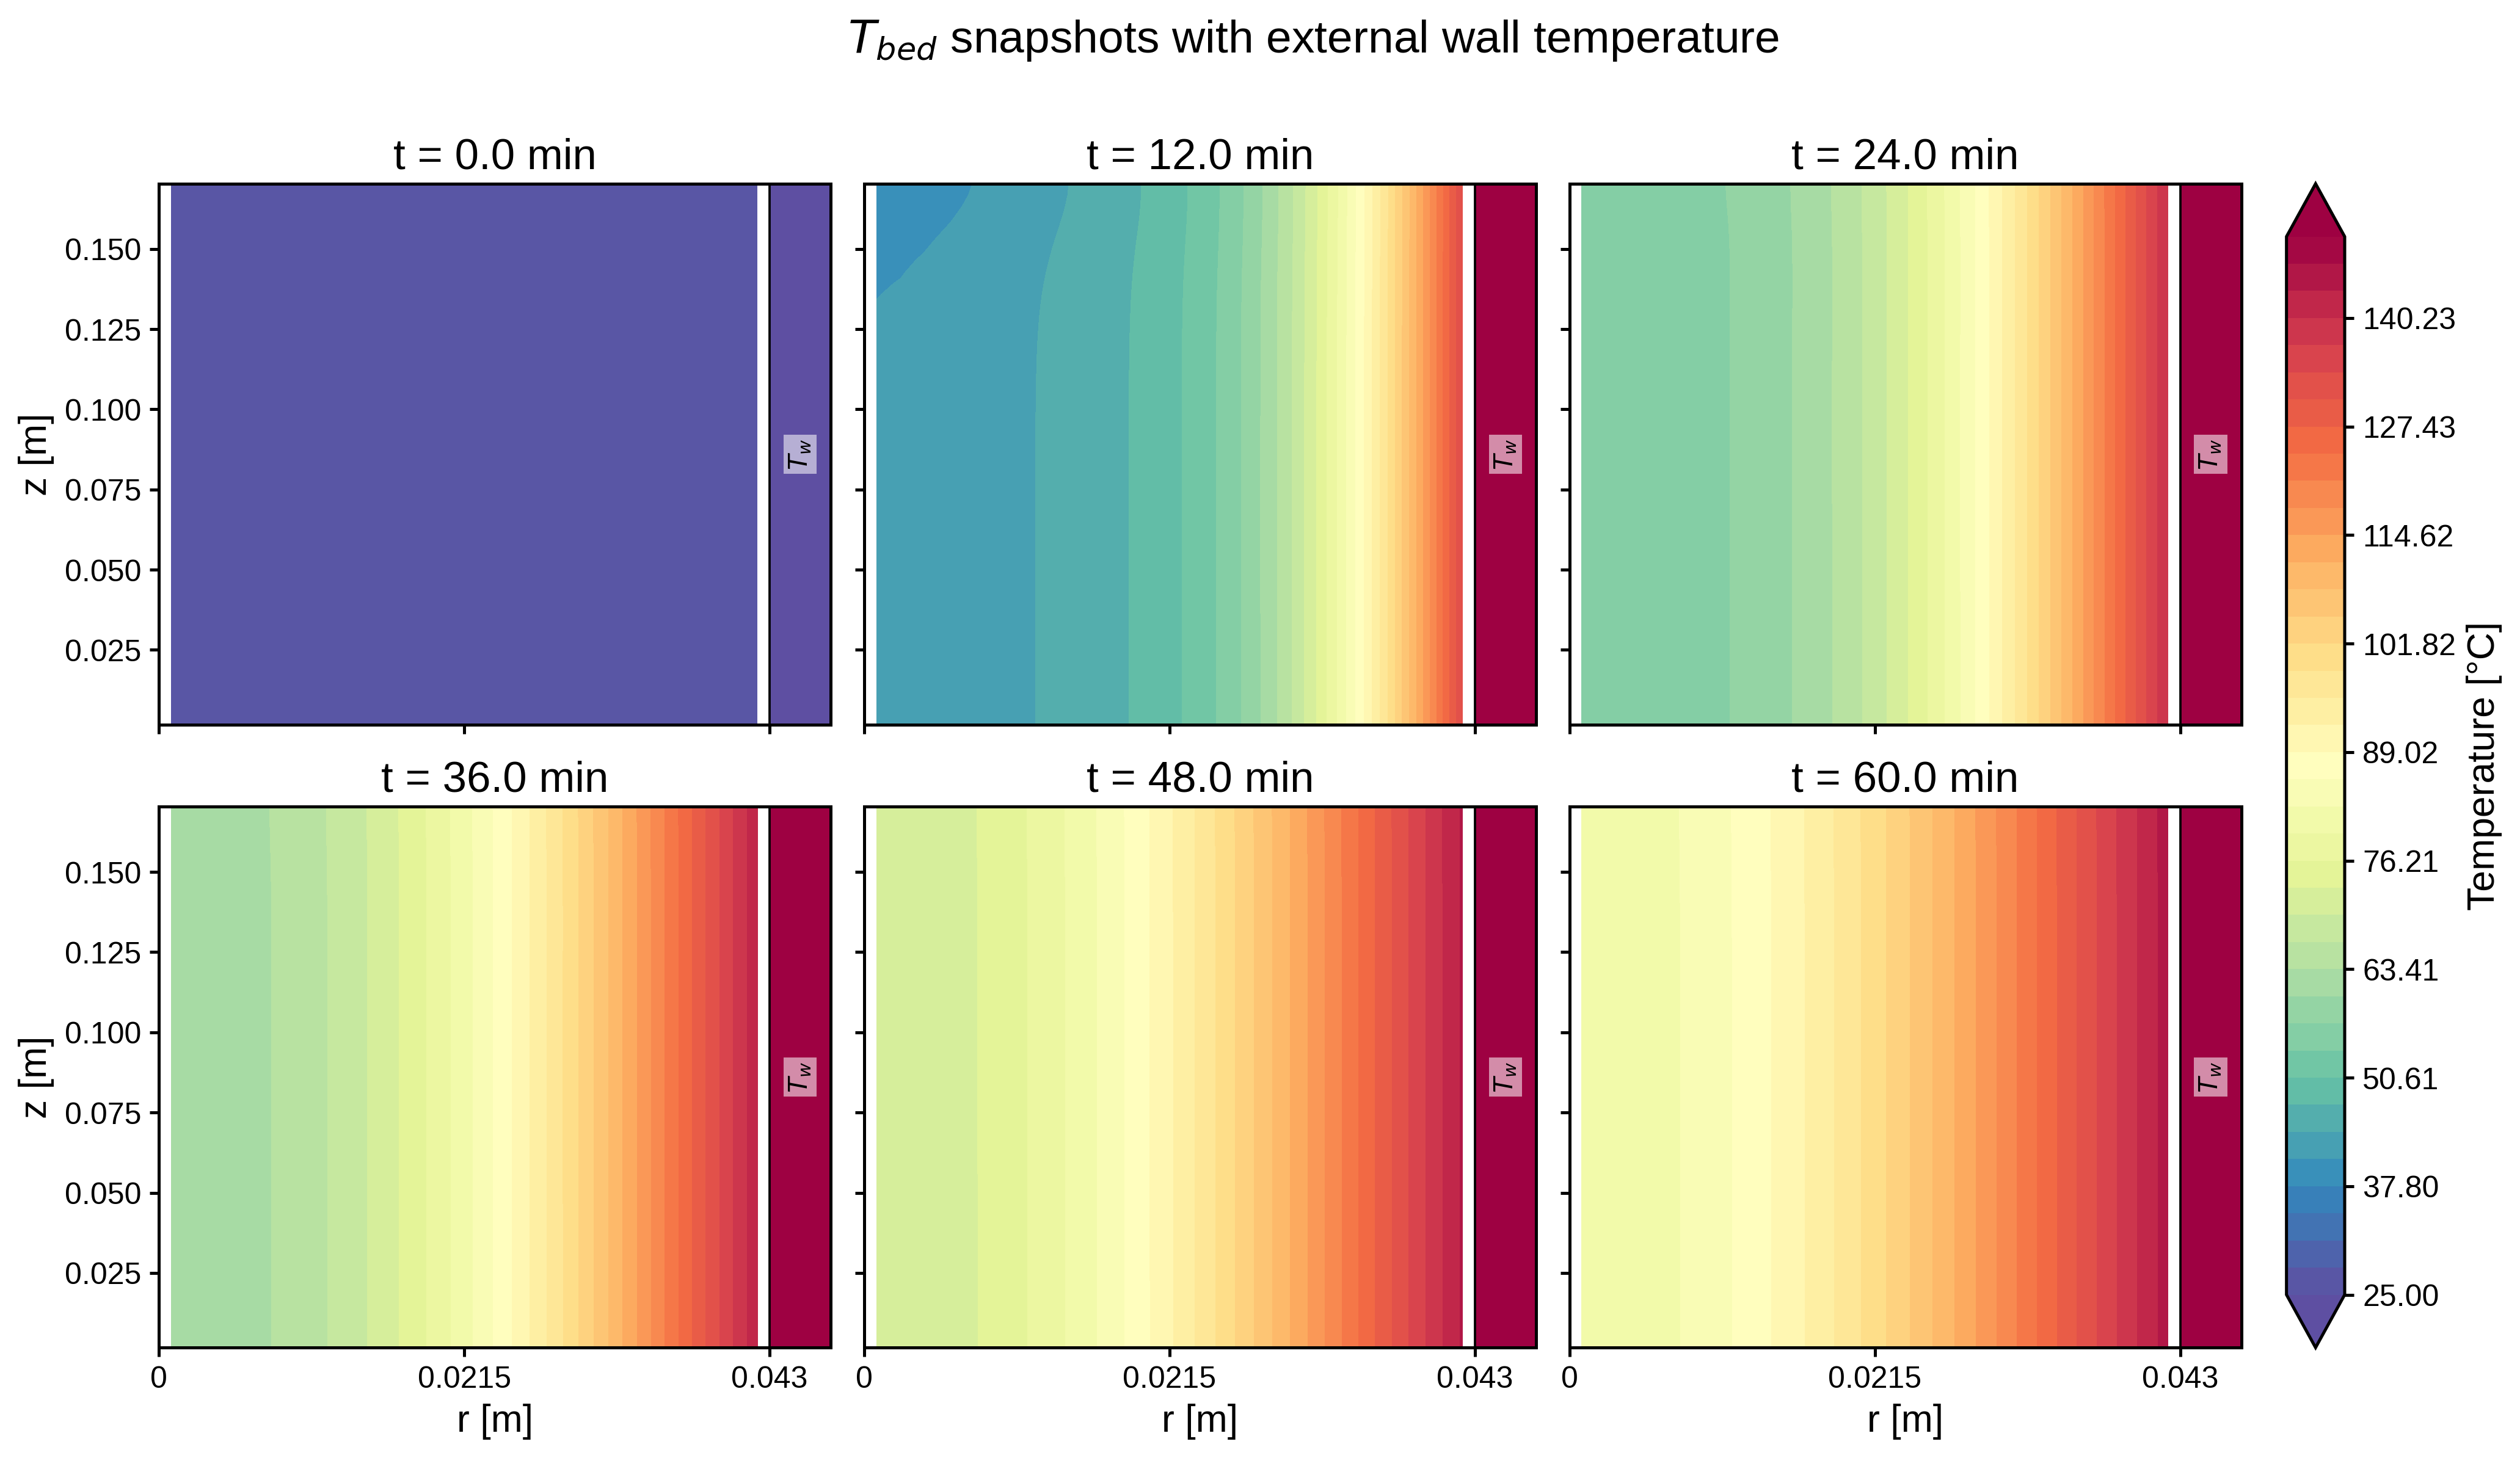

w_des: outlet composition


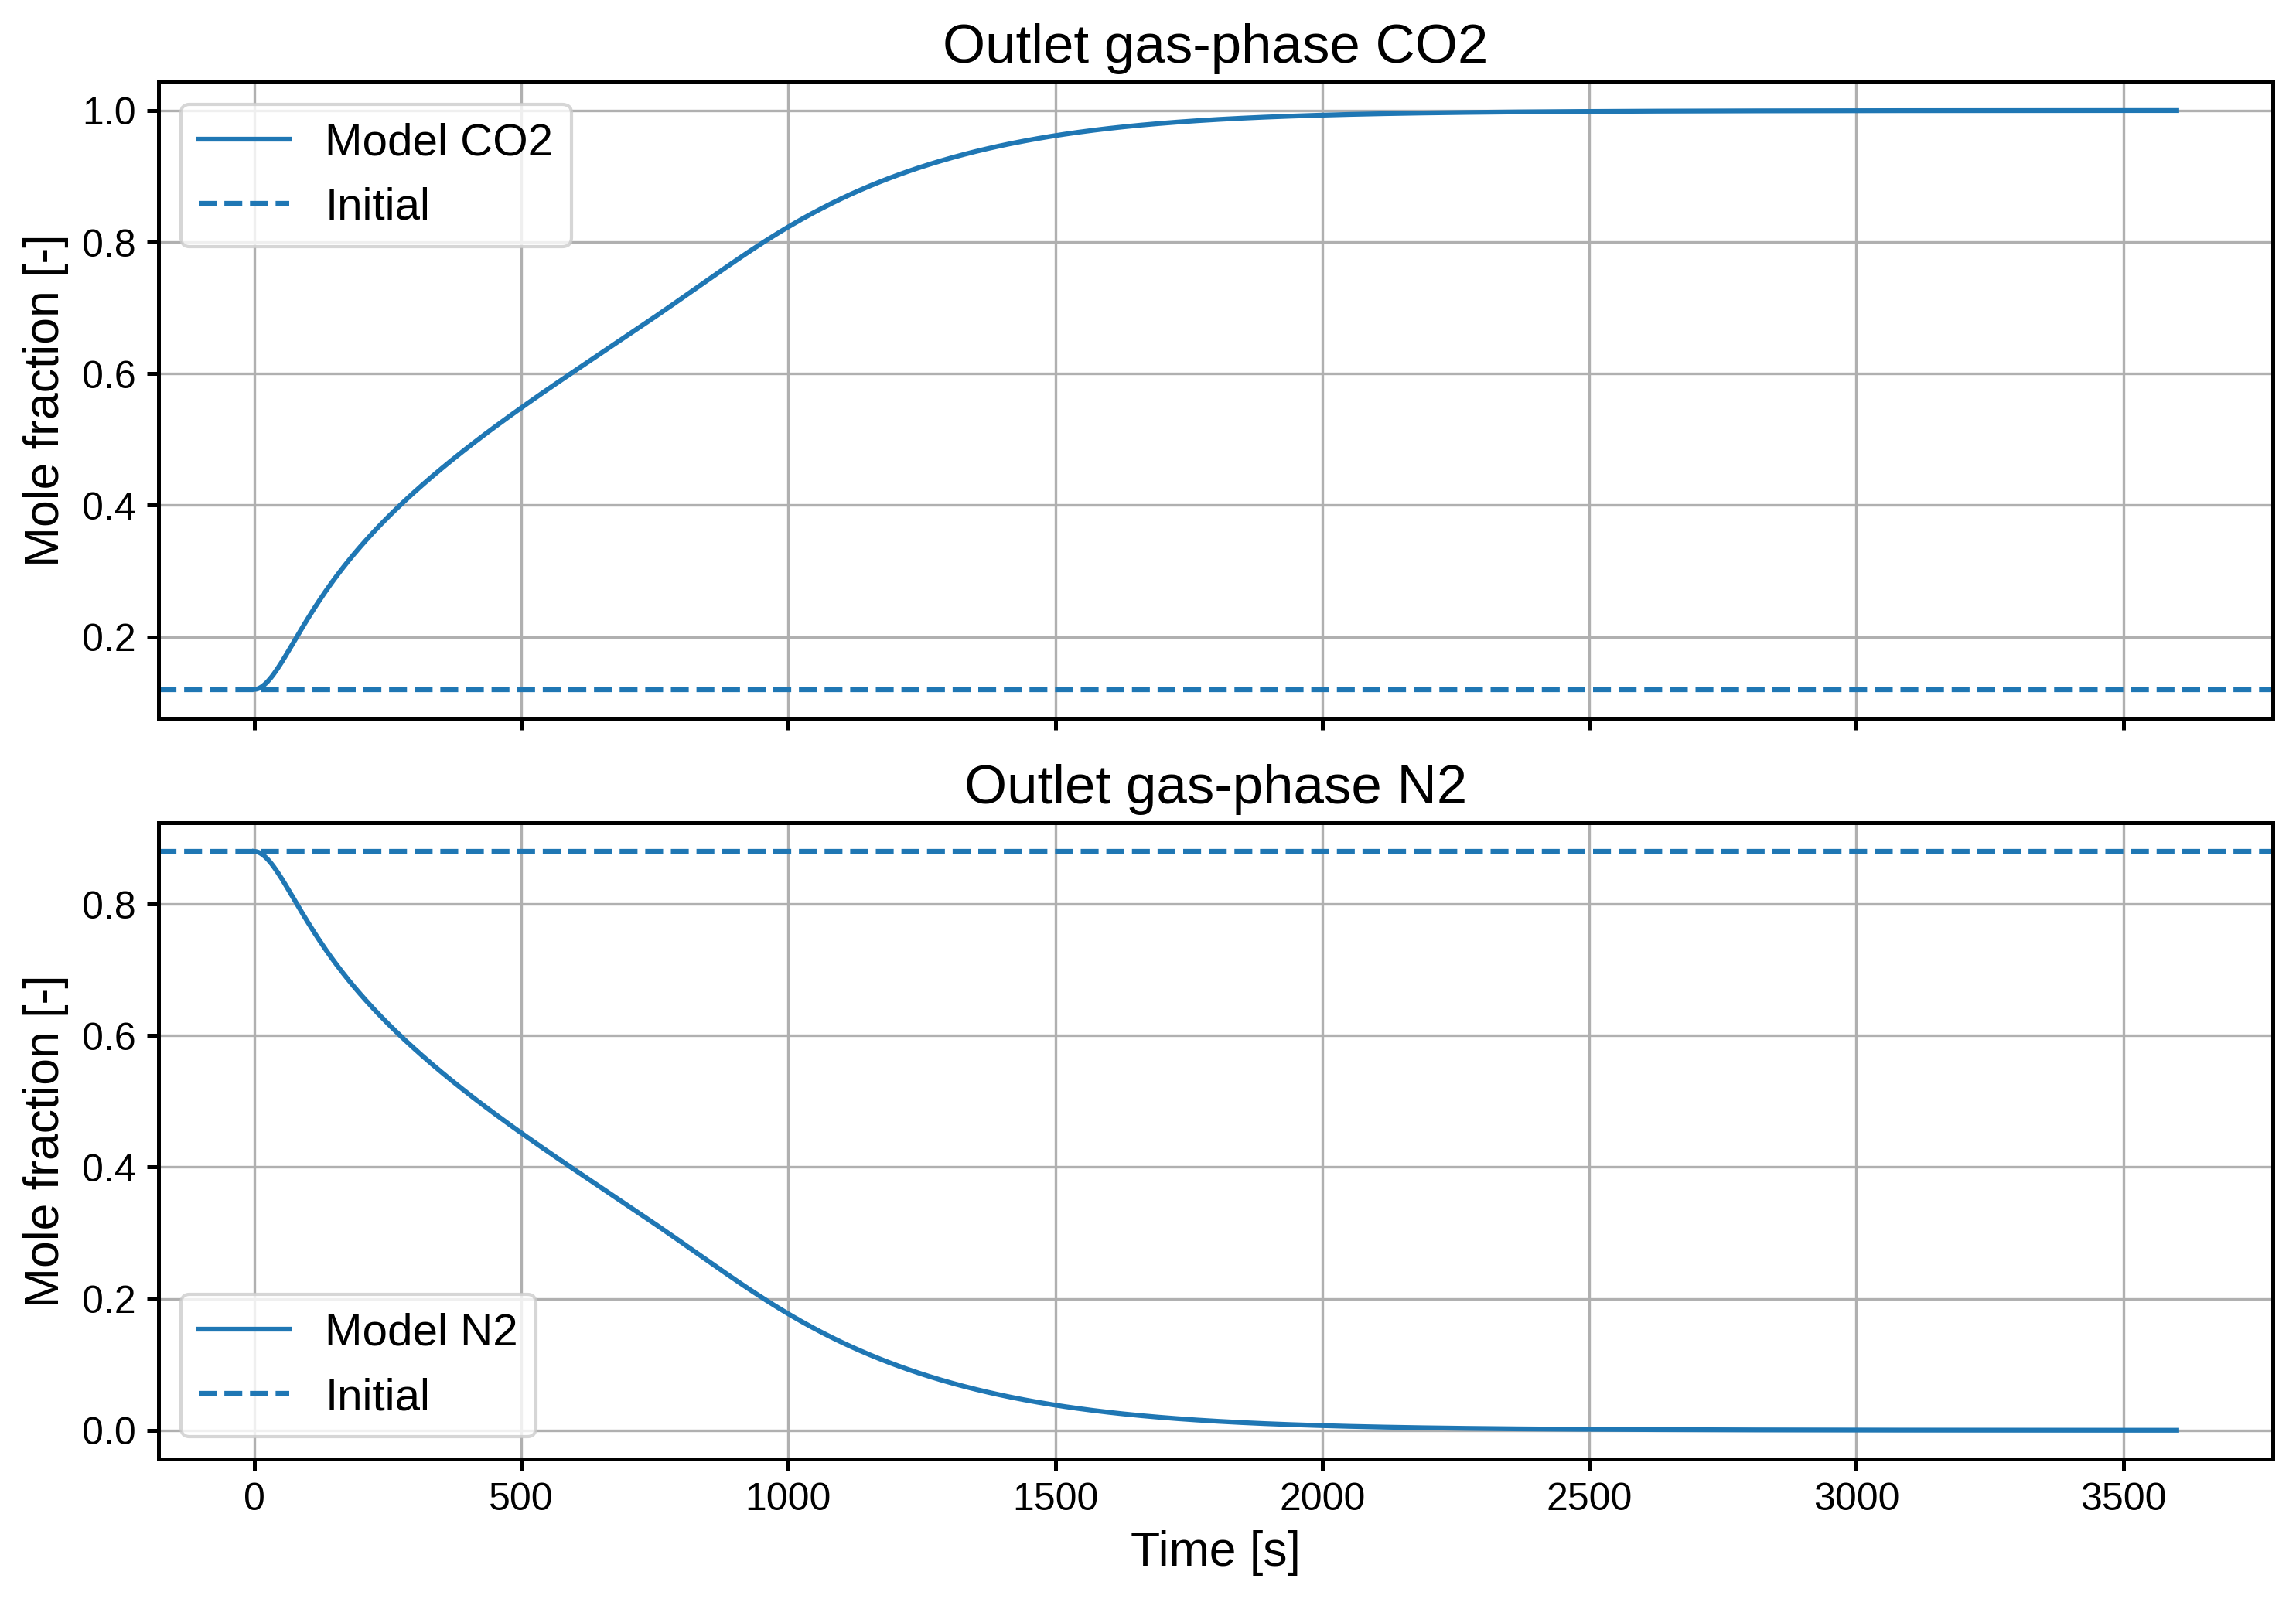

In [19]:
# Two exemplary figures of w_des: title -> path inside the run folder
figures = {
    "w_des: bed temperature over the radius and the length, and wall temperature": "w_des/profiles/internal_2D_profiles/w_des_Tbed_Twall_2D_snapshots.png",
    "w_des: outlet composition": "w_des/profiles/outlet_profiles/w_des_outlet_species.png",
}
# Show each figure under its title
for title, path in figures.items():
    print(title)
    display(Image(filename=result.results_folder / path, width=700))

What the figures show:
- **The wall** follows the jacket within two or three minutes.
- **The bed** warms from the wall inwards.
  - After an hour, the layer near the wall is close to 150 °C.
  - The axis is still around 80 °C.
  - A 1D model averages this radial difference away ([tutorial 04](04_1d_vs_2d.ipynb)).
- **The outlet**: the first gas out is the N2 that filled the column and the pores.
  - Within about 25 minutes the product is more than 95 % CO2.

## Quick experiments

What if you want to change just one thing to do a quick test?
- Load the preset we exported above, and put some `settings` on top of it:\
  `pydac.load_case(my_json_settings, settings={...})`.
- Here we change only the `w_des` jacket temperature: 100 °C and 200 °C.
- 150 °C is the case itself: we reuse the run above.
- Each temperature is a new case, with its own run folder: the run above stays as it is.
- The preset file does not change: these settings live only in this session.

The cell prints the log of the two new runs, as above.

In [20]:
rows = {}
for celsius in [100, 150, 200]:
    if celsius == 150:
        # The case itself: reuse the run above
        run = result
    else:
        # Our preset, one setting changed: a new case, a new run folder
        changed = pydac.load_case(my_json_settings, settings={
            "steps.w_des.thermal.jacket_temperature_K": celsius + 273.15,
        })
        run = pydac.run_steps(changed, overwrite=True)
    # Extract CO2 released, its share of what the startup loaded, and the product purity
    table = step_table(run)
    rows[f"{celsius} °C"] = {
        "CO2 released [g]": -table.loc["w_des", "CO2 change [g]"],
        "share of the loaded CO2 [%]": -100 * table.loc["w_des", "CO2 change [g]"] / table.loc["startup", "CO2 change [g]"],
        "product CO2 purity [%]": purity(table),
    }
sweep = pd.DataFrame(rows).T.round(1)
sweep

Overwrite: deleted /path/to/pyDAC/examples/notebooks/simulation_results/step_mode/tutorial_02_packed_bed_fcb0ee85
Run folder: /path/to/pyDAC/examples/notebooks/simulation_results/step_mode/tutorial_02_packed_bed_fcb0ee85

------------------------------------------------------------
           Thermodynamic + Kinetic Models Setup             
------------------------------------------------------------
Results will be saved in: simulation_results/step_mode/tutorial_02_packed_bed_fcb0ee85

                                               Starting Adsorption Cycle                                                
[TVSA] Starting step 'Startup' with solve=True, termination=time.

                                       Running Startup Step                                         
Execution mode      : solve=True (new simulation will be run)
Selected equilibrium: competitive Sips | Components: CO2, N2 | Dataset: hefti-2015-13x
Selected CO2 rate equation: LDF rate
Selected N2 rate equation: LDF r


Initializing inlet fluxes ...
Mass-flow-driven BC: setting inlet fluxes from feed values.

Runtime property summary...
Step=startup, T=298.15 K, p=101325.00 Pa, composition=feed.
CO2: cp=37.13 J/mol/K, mu=1.51E-05 Pa s, D_mix=1.62E-05 m2/s, Sc=0.87, Sh=9.14
N2: cp=29.12 J/mol/K, mu=1.76E-05 Pa s, D_mix=1.62E-05 m2/s, Sc=0.87, Sh=9.14
Fuller binary diffusivity [m2/s]: CO2-N2=1.62E-05
Mixture: rho=1.223499 kg/m3, mu=1.72E-05 Pa s, cp=30.084531 J/mol/K, lambda=0.024722 W/m/K
Re=24.42, Pr=0.70
Solid heat capacity: 1100.00 J/kg/K
Inlet mass flow [kg/s]: CO2=2.16E-04, N2=1.01E-03
Using spatial-mode results folder: simulation_results/step_mode/tutorial_02_packed_bed_fcb0ee85/2D_mode
Termination setup   : time

------------------------------------------------------------
               Solving PDE System for STARTUP               
------------------------------------------------------------
CVODE linear solver : sparse (direct sparse)
Using analytical sparsity pattern (generated in memory) wi

,CO2 released [g],share of the loaded CO2 [%],product CO2 purity [%]
100 °C,4.2,4.5,45.3
150 °C,23.0,25.0,80.8
200 °C,43.8,47.5,88.9


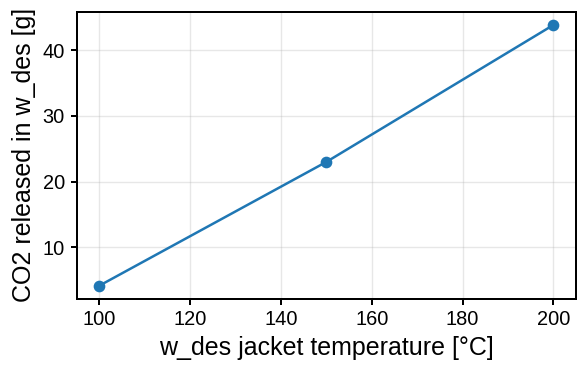

In [21]:
# CO2 released against the jacket temperature
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot([100, 150, 200], sweep["CO2 released [g]"], "o-")
ax.set_xlabel("w_des jacket temperature [°C]")
ax.set_ylabel("CO2 released in w_des [g]")
ax.grid(alpha=0.3)
fig.tight_layout()

13X holds CO2 strongly. In one hour:
- at 100 °C the bed releases only about 4 g of CO2;
- at 200 °C about 44 g, half of what it holds.

The N2 that leaves first is about the same in every run.\
So the purity rises with the CO2 released: from below 50 % at 100 °C to almost 90 % at 200 °C.

## The same from the terminal

Run these from the folder of this notebook:

```bash
# The case as it is
pydac steps --config ../cases/02_custom_case.json --overwrite

# One setting changed: w_des at 200 °C
pydac steps --config ../cases/02_custom_case.json --set steps.w_des.thermal.jacket_temperature_K=473.15 --overwrite

# Save the settings on top of the file as a new preset, without running anything
pydac validate --config ../cases/02_custom_case.json --set steps.w_des.thermal.jacket_temperature_K=473.15 --export-preset output_cases/02_preset_200C.json --overwrite-preset

# Save the complete case (as export_case above), without running anything
pydac steps --config ../cases/02_custom_case.json --export-case output_cases/02_full_case.json --overwrite-case --dry-run
```

`pydac validate --show-settings` lists every field path, with its default and its rules.

**Previous:** [Tutorial 01: First steps](01_first_steps.ipynb).\
**Next:** [Tutorial 03: A cycle at its periodic state](03_css_tvsa.ipynb).